# Minimum weight perfect matching implementation

**Reference paper**: https://arxiv.org/pdf/2105.13082

### First implementation: k=1 repetition code

Num qubits `n=3`; check matrix `H=[[1, 1, 0]; [0, 1, 1]]` rank 2; `n - rank(H) = 1` data qubit

We use `stim` repetition code simulator with a `Matching` object we define from our known check matrix 

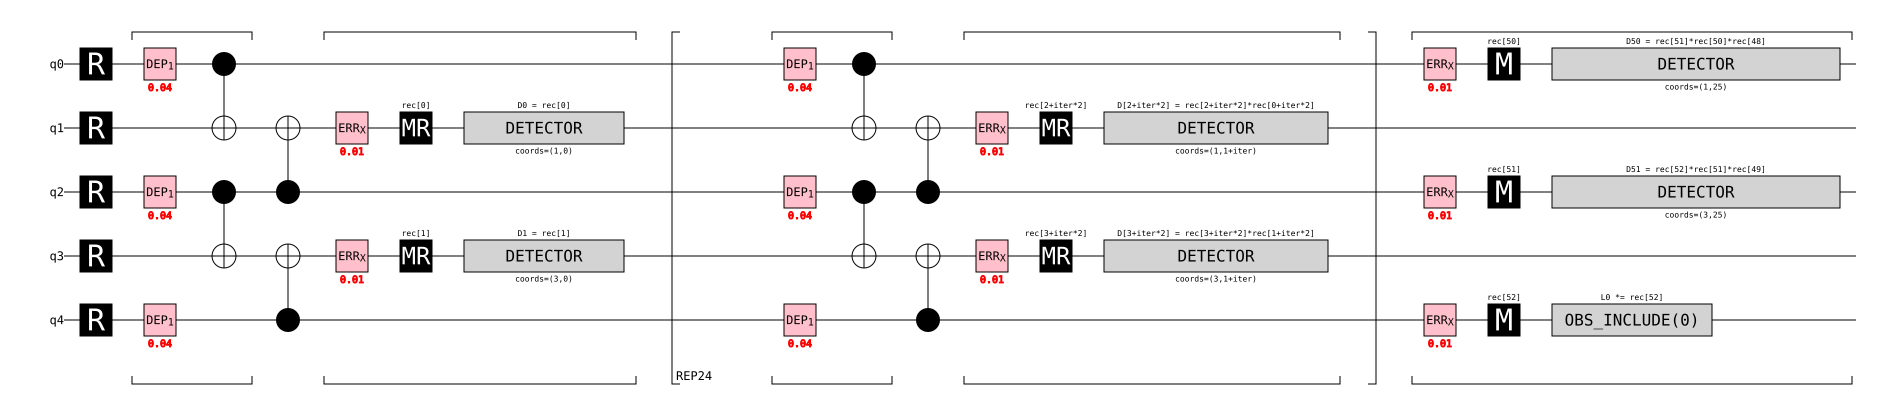

In [1]:
# construct stim simulator for data generation. repetition code circuit d=3
import stim
repetition_ckt = stim.Circuit.generated(
    "repetition_code:memory",
    rounds=25,
    distance=3,
    before_measure_flip_probability=0.01,
    before_round_data_depolarization=0.04
)
repetition_ckt.diagram('timeline-svg')

In [2]:
# show errors as 1 when simulating the circuit. tracks each channel
sampler = repetition_ckt.compile_sampler()
result = sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

_____________________________________________________


In [3]:
# now show errors tracking the detector
# results are much more sparse because we are tracking detected errors, not just whether error happens or not on channel
# foundation for error correction: flips come in pairs
detector_sampler = repetition_ckt.compile_detector_sampler()
result = detector_sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

____11________________________________________1_1___


## Matching decoder initialization

Now we initialize a detector error model (DEM) directly from the circuit data, and use it to construct a `pymatching.Matching` graph that encodes the syndrome data from the circuit as a MWPM graph

In [4]:
from pymatching import Matching

def mwpm_from_dem(meas_err_rate: float, data_err_rate: float, suppress_results: bool=False, distance: int=3, rounds: int=25):
    repetition_ckt = stim.Circuit.generated(
        "repetition_code:memory",
        rounds=rounds,
        distance=distance,
        before_measure_flip_probability=meas_err_rate,
        before_round_data_depolarization=data_err_rate,
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detector_sampler = repetition_ckt.compile_detector_sampler()
    # dynamically adjust detector shots based on error rate
    if meas_err_rate >= 1e-2:
        detector_shots = 10**3
    elif meas_err_rate < 1e-2 and meas_err_rate >= 1e-3:
        detector_shots = 10**4
    else:
        detector_shots = 10**5

    detection_events, observable_flips = detector_sampler.sample(shots=detector_shots, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

error_rate = mwpm_from_dem(0.04, 0.01)

MWPM error rate: 0.017
Missed 17 / 1000 detector errors.


Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

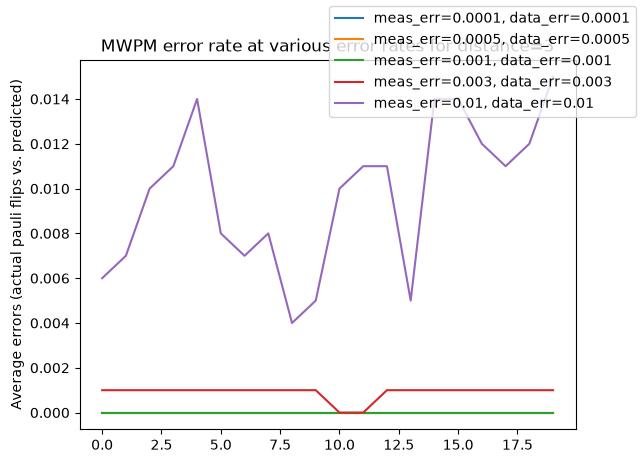

In [5]:
import matplotlib.pyplot as plt

def run_mwpm(meas_err_rate: float, data_err_rate: float, num_shots: int=20, distance: int=3):
    results = []
    for i in range(num_shots):
        prediction_error_rate = mwpm_from_dem(meas_err_rate, data_err_rate, distance=distance, suppress_results=True)
        results.append(prediction_error_rate)
    return results

# hardware-realistic error rates
error_rates = [
    (1e-4, 1e-4), 
    (5e-4, 5e-4), 
    (1e-3, 1e-3),
    (3e-3, 3e-3),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 3
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_3_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_3_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")

Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

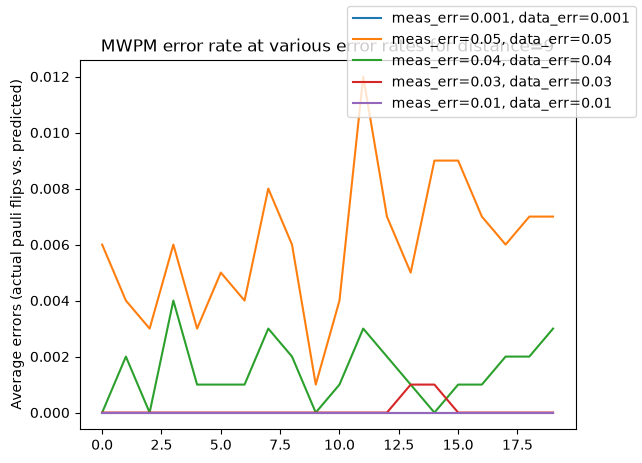

In [6]:
import numpy as np
# scale error rates up since distance is greater
error_rates = [
    (1e-3, 1e-3), 
    (5e-2, 5e-2), 
    (4e-2, 4e-2),
    (3e-2, 3e-2),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 9
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_9_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_9_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")
    

## Discussion of results so far

The near-perfect accuracy of MWPM on repetition code as demonstrated is an artifact of the type of errors that can possibly manifest on repetition code. Repetition code only protects against one Pauli type of error, depending on the parity-check ran from data to ancilla qubit. Here we track X-flips and MWPM is able to pick up on almost all of them because the DEM in repetition code is graphlike (TODO: need to prove this mathematically to improve quality of discussion), and MWPM is a graph algorithm. 

Practical limitations: 
- Real hardware has 3 types of Pauli flips (X, Z, Y) that repetition code can only see one of
- Since the repetition code DEM is graphlike, it cannot represent hyperedges (>2 correlated nodes for given error pattern); hyperedges are more common in surface code topologies so MWPM breaks down (TODO: run MWPM against surface code and demonstrate worse accuracy)

In [11]:
# demonstrate that MWPM gets cooked by surface code. first redefine functions
distance = 3
# add error rate for hook errors (after CNOT gate error, not included in repetition code). produces hyperedges
error_rates = [
    5e-3,
    4e-3,
    3e-3,
    2e-3,
    1e-3
]

def surface_mwpm_from_dem(p_err: float, suppress_results: bool=False, distance: int=3, rounds: int=5):
    repetition_ckt = stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        rounds=rounds,
        distance=distance,
        before_measure_flip_probability=p_err,
        before_round_data_depolarization=p_err,
        after_clifford_depolarization=p_err
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detector_sampler = repetition_ckt.compile_detector_sampler()

    detector_shots = 2*10**5

    detection_events, observable_flips = detector_sampler.sample(shots=detector_shots, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

def surface_run_mwpm(p_err: float, num_shots: int=20, distance: int=3):
    results = []
    for i in range(num_shots):
        prediction_error_rate = surface_mwpm_from_dem(p_err, distance=distance, suppress_results=True)
        results.append(prediction_error_rate)
    return results

Text(0, 0.5, 'Logical error rate per shot')

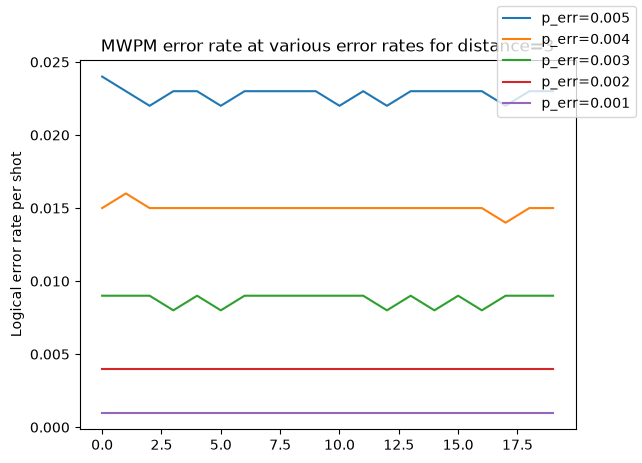

In [12]:
result = []
for p in error_rates:
    surface_error_rate = surface_run_mwpm(p_err=p, distance=distance)
    result.append((surface_error_rate, p))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    p_err = res[1]
    ax.plot(res[0], label=f"p_err={p_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Logical error rate per shot")

**Comments**: 
- with shots=1000 we don't get enough shots for errors to occur with p_err=0.001
- for increasing error past that we can see how cooked mwpm is for surface code. errors no longer coerced to be graphlike

In [9]:
c = stim.Circuit.generated("surface_code:rotated_memory_z", distance=3, rounds=3,
        before_measure_flip_probability=0.01, before_round_data_depolarization=0.01)
print(c)                              # read the DETECTOR lines
# print(c.detector_error_model())
# c.diagram('timeline-svg')

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.01) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
TICK
X_ERROR(0.01) 2 9 11 13 14 16 18 25
MR 2 9 11 13 14 16 18 25
DETECTOR(0, 4, 0) rec[-4]
DETECTOR(2, 2, 0) rec[-7]
DETECTOR(4, 4, 0) rec[-2]
DETECTOR(6, 2, 0) rec[-5]
REPEAT 2 {
    TICK
    DEPOLARIZE1(0.01) 1 3 5 8 10 12 15 17 19
    H 2 11 16 25
    TICK
    CX 2 3 16 17 11 12 15 14 10 9 19 18
    TICK
    CX 2 1 16 15 11 10 8 14 3 9 12 18


In [10]:
hit = stim.DetectorErrorModel("error(1) D2 D5 D6 D9")
for x in c.explain_detector_error_model_errors(dem_filter=hit,
                                               reduce_to_one_representative_error=True):
    print(x)

ExplainedError {
    dem_error_terms: D2[coords 4,4,0] D5[coords 2,2,1] D6[coords 4,2,1] D9[coords 2,4,1]
    [no single circuit error had these exact symptoms]
}


## Baseline metric: logical error per round $\varepsilon$

note: I had claude execute this baseline task on its own because scope was clearly defined and just needed to get info to guide us.

The per-shot logical error rate grows with the number of rounds $r$ for **every** decoder, the optimal one included. Each round has some chance $\varepsilon$ of flipping the logical observable, and an even number of flips cancels:

$$\mathrm{LER}(r) = \tfrac12\big(1 - A\,(1-2\varepsilon)^r\big)$$

so $\mathrm{LER}\to\tfrac12$ as $r\to\infty$ whatever the decoder. This is why the earlier 25-round plots looked like a coin flip at high $p$. The number to compare decoders on is $\varepsilon$, and it should not depend on $r$.

$A\le1$ absorbs the state-preparation and final-readout boundaries, which are not "per round". Here $A\approx1$, so the correction is small, but it matters for short runs and on hardware data.

**Method.** Write $F(r) = 1-2\,\mathrm{LER}(r)$. Then $\ln F = \ln A + r\ln(1-2\varepsilon)$ is a straight line in $r$. Fit it by weighted least squares across several $r$, with weights from the binomial error on each LER point, and get $\varepsilon = \tfrac12(1-e^{\text{slope}})$.

**Setup.** $d=3$ rotated surface code, memory-Z, uniform $p$ on all four Stim channels (`after_clifford`, `before_round_data`, `before_measure`, `after_reset`). That is the same convention as `data_pipe.ipynb` and `research_log/mwpm_headroom.md`. Cell 9 above leaves out `after_reset`, so its numbers are not directly comparable. Sampling stops at `max_errors` logical failures or `max_shots`, whichever comes first, so every point has a similar relative error.

In [ ]:
import numpy as np
import stim
import matplotlib.pyplot as plt
from pymatching import Matching

def memory_circuit(d: int, r: int, p: float) -> stim.Circuit:
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=r,
        after_clifford_depolarization=p,
        before_round_data_depolarization=p,
        before_measure_flip_probability=p,
        after_reset_flip_probability=p,
    )

def mwpm_failures(d: int, r: int, p: float, max_shots: int=2_000_000, max_errors: int=1_000, batch: int=100_000, seed: int=None):
    """Sample until max_errors logical failures or max_shots. Returns (failures, shots)."""
    circuit = memory_circuit(d, r, p)
    matcher = Matching.from_detector_error_model(circuit.detector_error_model(decompose_errors=True))
    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = failures = 0
    while shots < max_shots and failures < max_errors:
        n = min(batch, max_shots - shots)
        detection_events, observable_flips = sampler.sample(n, separate_observables=True)
        predictions = matcher.decode_batch(detection_events)
        failures += int(np.sum(predictions[:, 0] != observable_flips[:, 0]))
        shots += n
    return failures, shots

def fit_epsilon(rounds, failures, shots):
    """Weighted fit of ln(1 - 2 LER) = ln A + r ln(1 - 2 eps). Returns (eps, eps_std, A)."""
    rounds, failures, shots = map(np.asarray, (rounds, failures, shots))
    ler = failures / shots
    F = 1 - 2 * ler
    sigma_F = 2 * np.sqrt(ler * (1 - ler) / shots)
    # drop points whose fidelity is indistinguishable from 0 (LER ~ 1/2): log is undefined / pure noise there
    keep = F > 3 * sigma_F
    if keep.sum() < 2:
        return np.nan, np.nan, np.nan
    sigma_lnF = sigma_F[keep] / F[keep]
    (slope, intercept), cov = np.polyfit(rounds[keep], np.log(F[keep]), 1, w=1 / sigma_lnF, cov="unscaled")
    eps = (1 - np.exp(slope)) / 2
    eps_std = np.exp(slope) / 2 * np.sqrt(cov[0, 0])
    return eps, eps_std, np.exp(intercept)

def single_point_epsilon(r, ler):
    """Naive eps from one r (assumes A = 1)."""
    return 0.5 * (1 - (1 - 2 * ler) ** (1 / r))

In [ ]:
distance = 3
rounds_list = [3, 5, 10, 25, 50, 100]
p_list = [1e-3, 2e-3, 3e-3, 5e-3]

eps_results = {}  # p -> dict of arrays + fit
for p in p_list:
    failures, shots = zip(*(mwpm_failures(distance, r, p, seed=0) for r in rounds_list))
    eps, eps_std, A = fit_epsilon(rounds_list, failures, shots)
    eps_results[p] = dict(failures=np.array(failures), shots=np.array(shots), eps=eps, eps_std=eps_std, A=A)

print(f"MWPM baseline, d={distance}, rotated memory-Z, uniform p on 4 channels")
print(f"{'p':>7} | {'eps / round':>20} | {'A':>6} | " + " | ".join(f"LER r={r:<3}" for r in rounds_list))
for p, res in eps_results.items():
    ler = res["failures"] / res["shots"]
    print(f"{p:7.0e} | {res['eps']:.3e} ± {res['eps_std']:.1e} | {res['A']:.3f} | " + " | ".join(f"{x:9.2e}" for x in ler))

print("\nSingle-point eps (assumes A = 1): slightly high at small r from the boundary rounds, flat beyond r ~ 10:")
for p, res in eps_results.items():
    ler = res["failures"] / res["shots"]
    print(f"{p:7.0e} | " + " | ".join(f"r={r:<3} {single_point_epsilon(r, x):.2e}" for r, x in zip(rounds_list, ler)))

MWPM baseline, d=3, rotated memory-Z, uniform p on 4 channels
      p |          eps / round |      A | LER r=3   | LER r=5   | LER r=10  | LER r=25  | LER r=50  | LER r=100
  1e-03 | 2.404e-04 ± 3.6e-06 | 1.000 |  7.43e-04 |  1.30e-03 |  2.53e-03 |  6.24e-03 |  1.16e-02 |  2.31e-02
  2e-03 | 9.257e-04 ± 8.2e-06 | 1.000 |  2.87e-03 |  4.92e-03 |  9.37e-03 |  2.31e-02 |  4.41e-02 |  8.45e-02
  3e-03 | 2.016e-03 ± 1.4e-05 | 0.999 |  6.47e-03 |  1.06e-02 |  1.99e-02 |  4.82e-02 |  9.19e-02 |  1.67e-01
  5e-03 | 5.340e-03 ± 2.9e-05 | 0.997 |  1.71e-02 |  2.75e-02 |  5.25e-02 |  1.20e-01 |  2.08e-01 |  3.28e-01

Single-point eps (assumes A = 1): slightly high at small r from the boundary rounds, flat beyond r ~ 10:
  1e-03 | r=3   2.48e-04 | r=5   2.60e-04 | r=10  2.54e-04 | r=25  2.51e-04 | r=50  2.34e-04 | r=100 2.36e-04
  2e-03 | r=3   9.59e-04 | r=5   9.88e-04 | r=10  9.45e-04 | r=25  9.45e-04 | r=50  9.23e-04 | r=100 9.25e-04
  3e-03 | r=3   2.17e-03 | r=5   2.13e-03 | r=10  2.02e-03 |

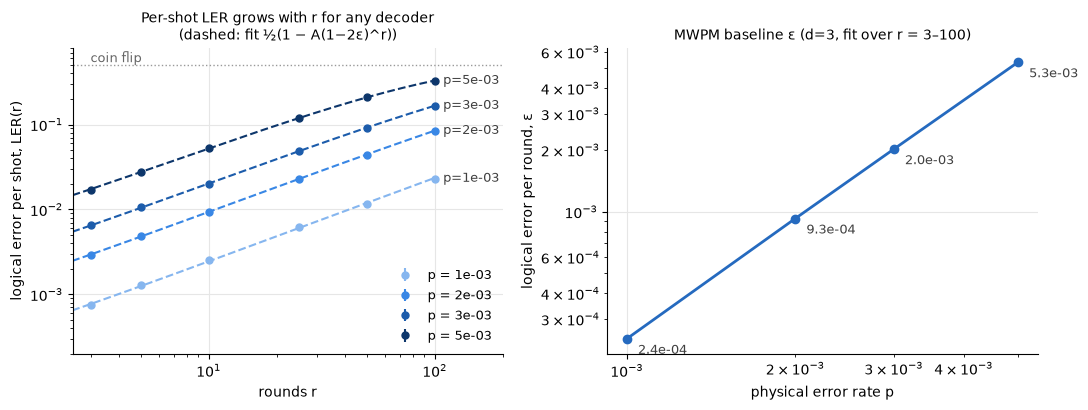

In [ ]:
# ordinal blue ramp: lighter = lower p
colors = dict(zip(p_list, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))
r_grid = np.linspace(1, max(rounds_list), 200)

fig, (ax_ler, ax_eps) = plt.subplots(1, 2, figsize=(11, 4.2))

for p, res in eps_results.items():
    ler = res["failures"] / res["shots"]
    err = np.sqrt(ler * (1 - ler) / res["shots"])
    c = colors[p]
    ax_ler.errorbar(rounds_list, ler, yerr=err, fmt="o", ms=5, color=c, label=f"p = {p:.0e}")
    ax_ler.plot(r_grid, 0.5 * (1 - res["A"] * (1 - 2 * res["eps"]) ** r_grid), "--", lw=1.5, color=c)
    ax_ler.annotate(f"p={p:.0e}", (rounds_list[-1], ler[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color="0.25")
ax_ler.axhline(0.5, color="0.6", lw=1, ls=":")
ax_ler.text(3, 0.5, "coin flip", va="bottom", fontsize=9, color="0.4")
ax_ler.set_xscale("log")
ax_ler.set_yscale("log")
ax_ler.set_xlabel("rounds r")
ax_ler.set_ylabel("logical error per shot, LER(r)")
ax_ler.set_title("Per-shot LER grows with r for any decoder\n(dashed: fit ½(1 − A(1−2ε)^r))", fontsize=10)
ax_ler.set_xlim(2.5, 200)
ax_ler.set_ylim(top=0.8)

ps = np.array(p_list)
eps = np.array([eps_results[p]["eps"] for p in p_list])
eps_std = np.array([eps_results[p]["eps_std"] for p in p_list])
ax_eps.errorbar(ps, eps, yerr=eps_std, fmt="o-", ms=6, lw=2, color="#256abf")
for p, e in zip(ps, eps):
    ax_eps.annotate(f"{e:.1e}", (p, e), xytext=(8, -4), textcoords="offset points", ha="left", va="top", fontsize=9, color="0.25")
ax_eps.set_xscale("log")
ax_eps.set_yscale("log")
ax_eps.set_xlabel("physical error rate p")
ax_eps.set_ylabel("logical error per round, ε")
ax_eps.set_title(f"MWPM baseline ε (d={distance}, fit over r = {rounds_list[0]}–{rounds_list[-1]})", fontsize=10)

for ax in (ax_ler, ax_eps):
    ax.grid(True, which="major", color="0.9", lw=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
ax_ler.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

**Reading the baseline.**

- $\varepsilon$ is flat in $r$: the single-point estimates agree with the fit from $r\approx10$ on. MWPM does not get worse on longer runs. The rise in per-shot LER is the same compounding that every decoder suffers.
- A learned decoder beats this baseline only if its fitted $\varepsilon$ is lower at the same $(d, p)$, with non-overlapping error bars. Evaluate it on the same `rounds_list`, with the same `fit_epsilon`.
- $\varepsilon \propto p^{2}$ on the right panel, as expected for $d=3$: two faults are needed, since $(d+1)/2 = 2$.
- Exact optimal-decoder headroom at $r=3$ is 1.19–1.26× (`research_log/mwpm_headroom.md`). The headroom at $r = 25$–$100$ has not been measured yet.

## Where the MWPM gap comes from: correlation vs degeneracy

note: Claude ran this one too (open question in `research_log/README.md`). Derivation in `research_log/mwpm_gap_derivation.md` §3.

MWPM differs from the optimal decoder in two ways:
- **model:** it uses the graph model $P_G$, the product of edge marginals. The true DEM has hyperedges whose pieces are correlated (the **correlation** term).
- **rule:** it takes the single most likely error (max) instead of summing over every error in the logical class (the **degeneracy** term).

Fix one, the other, or both, and you get four decoders. Each one is scored exactly against the true $P(s, L)$:

| | max | sum |
|---|---|---|
| **graph model** | MWPM | graph-sum |
| **true DEM** | true-max (hypergraph most-likely-error) | optimal |

The max version uses the same XOR fold that builds $P(s,L)$, with `max` in place of `+`: $M \leftarrow \max\big((1-p_j)M,\; p_j M[\,\cdot \oplus \text{mask}_j]\big)$. This is exact because max distributes over products of nonnegative factors. As a check, graph-max must reproduce PyMatching on every syndrome.

The split depends on which term you fix first, so the bar chart shows the Shapley average of the two orderings. The per-syndrome table also shows which single fix flips each of MWPM's wrong calls back to the optimal one.

Limit: $r=3$ only (2^25 outcomes, ~40 s per $p$).

d=3, r=3, rotated memory-Z, uniform p on 4 channels. Exact, no sampling.
graph = MWPM's model (product of edge marginals), true = full DEM with hyperedges
max = single most likely error, sum = whole class (optimal)

      p |       opt |  true_max | graph_sum |      MWPM | MWPM/opt |         corr |        degen | check
  1e-03 | 6.101e-04 | 6.183e-04 | 7.647e-04 | 7.699e-04 |   1.262x | 1.53e-04  96% | 6.71e-06   4% | PyMatching mismatch 0e+00
  2e-03 | 2.415e-03 | 2.449e-03 | 2.972e-03 | 2.996e-03 |   1.241x | 5.52e-04  95% | 2.93e-05   5% | PyMatching mismatch 0e+00
  3e-03 | 5.365e-03 | 5.449e-03 | 6.498e-03 | 6.556e-03 |   1.222x | 1.12e-03  94% | 7.08e-05   6% | PyMatching mismatch 0e+00
  5e-03 | 1.444e-02 | 1.472e-02 | 1.701e-02 | 1.718e-02 |   1.189x | 2.51e-03  92% | 2.21e-04   8% | PyMatching mismatch 0e+00

Order dependence: share of the gap that is correlation, fixing it first vs last
  1e-03 | first  95% | last  97%
  2e-03 | first  94% | last  96%
  3e-03 | first  93% | l

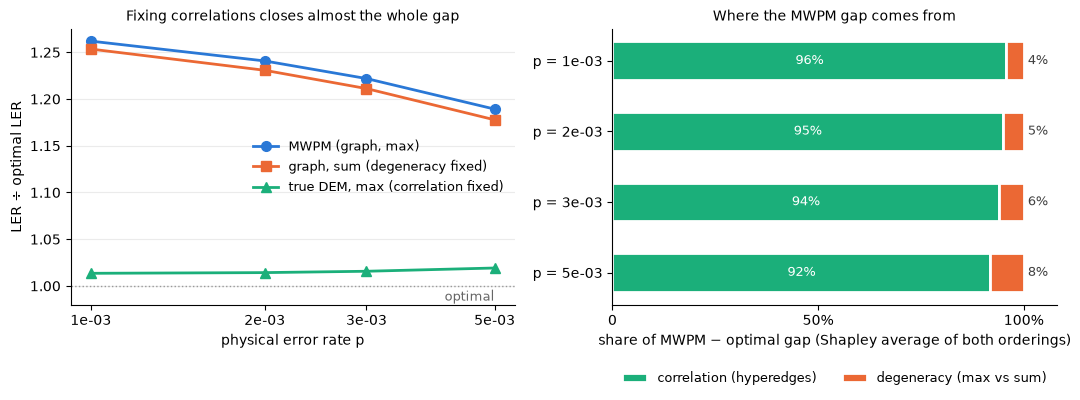

In [1]:
# Exact split of the MWPM-to-optimal gap into correlation and degeneracy, summed over all syndromes.
# d=3, r=3 (24 detectors, 2^25 outcomes). ~40 s and ~1.5 GB per p.
import numpy as np
import stim
import matplotlib.pyplot as plt
from pymatching import Matching

def memory_circuit(d: int, r: int, p: float) -> stim.Circuit:
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=r,
        after_clifford_depolarization=p,
        before_round_data_depolarization=p,
        before_measure_flip_probability=p,
        after_reset_flip_probability=p,
    )

def true_mechanisms(circuit: stim.Circuit):
    """Undecomposed DEM lines as (p, bitmask over detectors + L0 at bit n). Hyperedges kept whole."""
    dem = circuit.detector_error_model(decompose_errors=False).flattened()
    n = dem.num_detectors
    mechs = []
    for inst in dem:
        if inst.type != "error":
            continue
        mask = 0
        for t in inst.targets_copy():
            if t.is_relative_detector_id():
                mask ^= 1 << t.val
            elif t.is_logical_observable_id():
                mask ^= 1 << n
        mechs.append((inst.args_copy()[0], mask))
    return mechs, n

def graph_mechanisms(matcher: Matching, n: int):
    """PyMatching's own edges (merged p', L0 from fault_ids), treated as independent: MWPM's model P_G."""
    mechs = []
    for u, v, data in matcher.edges():
        mask = 1 << u
        if v is not None:
            mask ^= 1 << v
        if 0 in data["fault_ids"]:
            mask ^= 1 << n
        mechs.append((data["error_probability"], mask))
    return mechs

def fold(mechs, n: int, rule: str) -> np.ndarray:
    """rule='sum': P[L, s], the sum over all errors with signature (s, L).
    rule='max': the probability of the single most likely such error (max-product)."""
    P = np.zeros(2 ** (n + 1))
    P[0] = 1.0
    idx = np.arange(2 ** (n + 1), dtype=np.uint32)
    for p, mask in mechs:
        if rule == "sum":
            P = (1 - p) * P + p * P[idx ^ mask]
        else:
            P = np.maximum((1 - p) * P, p * P[idx ^ mask])
    return P.reshape(2, 2 ** n)

def gap_split(p: float, d: int = 3, r: int = 3, min_prob: float = 1e-14):
    """Exact LER of the four (model, rule) decoders, all scored on the true P(s, L)."""
    circuit = memory_circuit(d, r, p)
    true_mechs, n = true_mechanisms(circuit)
    matcher = Matching.from_detector_error_model(circuit.detector_error_model(decompose_errors=True))
    graph_mechs = graph_mechanisms(matcher, n)

    P = fold(true_mechs, n, "sum")
    keep = np.nonzero(P.sum(0) > min_prob)[0]
    P = P[:, keep]
    pred = {"true_sum": P[1] > P[0]}
    for name, mechs, rule in [("true_max", true_mechs, "max"), ("graph_sum", graph_mechs, "sum"), ("graph_max", graph_mechs, "max")]:
        pred[name] = (lambda M: M[1] > M[0])(fold(mechs, n, rule)[:, keep])
    bits = ((keep[:, None] >> np.arange(n)) & 1).astype(np.uint8)
    pymatching_pred = matcher.decode_batch(bits)[:, 0].astype(bool)

    cols = np.arange(len(keep))
    ler = {k: float(P[(~v).astype(int), cols].sum()) for k, v in pred.items()}
    mismatch = float(P[:, pred["graph_max"] != pymatching_pred].sum())

    # per-syndrome view: where MWPM disagrees with optimal, which single fix recovers the optimal call
    wrong = pred["graph_max"] != pred["true_sum"]
    w = np.abs(P[0] - P[1])[wrong]
    by_corr = pred["true_max"][wrong] == pred["true_sum"][wrong]
    by_degen = pred["graph_sum"][wrong] == pred["true_sum"][wrong]
    fixed_by = {
        "correlation only": w[by_corr & ~by_degen].sum(),
        "degeneracy only": w[~by_corr & by_degen].sum(),
        "either": w[by_corr & by_degen].sum(),
        "needs both": w[~by_corr & ~by_degen].sum(),
    }
    fixed_by = {k: float(v / w.sum()) for k, v in fixed_by.items()}
    return dict(ler=ler, mismatch=mismatch, fixed_by=fixed_by, n_wrong=int(wrong.sum()), n_syndromes=len(keep))

split_p_list = [1e-3, 2e-3, 3e-3, 5e-3]
split_results = {p: gap_split(p) for p in split_p_list}

print("d=3, r=3, rotated memory-Z, uniform p on 4 channels. Exact, no sampling.")
print("graph = MWPM's model (product of edge marginals), true = full DEM with hyperedges")
print("max = single most likely error, sum = whole class (optimal)\n")
print(f"{'p':>7} | {'opt':>9} | {'true_max':>9} | {'graph_sum':>9} | {'MWPM':>9} | {'MWPM/opt':>8} | {'corr':>12} | {'degen':>12} | check")
for p, res in split_results.items():
    L = res["ler"]
    gap = L["graph_max"] - L["true_sum"]
    corr = 0.5 * ((L["graph_max"] - L["true_max"]) + (L["graph_sum"] - L["true_sum"]))
    degen = 0.5 * ((L["graph_max"] - L["graph_sum"]) + (L["true_max"] - L["true_sum"]))
    res.update(gap=gap, corr=corr, degen=degen)
    print(f"{p:7.0e} | {L['true_sum']:.3e} | {L['true_max']:.3e} | {L['graph_sum']:.3e} | {L['graph_max']:.3e} | "
          f"{L['graph_max'] / L['true_sum']:7.3f}x | {corr:.2e} {corr / gap:4.0%} | {degen:.2e} {degen / gap:4.0%} | "
          f"PyMatching mismatch {res['mismatch']:.0e}")

print("\nOrder dependence: share of the gap that is correlation, fixing it first vs last")
for p, res in split_results.items():
    L, gap = res["ler"], res["gap"]
    print(f"{p:7.0e} | first {(L['graph_max'] - L['true_max']) / gap:4.0%} | last {(L['graph_sum'] - L['true_sum']) / gap:4.0%}")

print("\nSyndromes where MWPM's call differs from optimal, weighted by |P(s,0) - P(s,1)|: which fix alone recovers it")
for p, res in split_results.items():
    print(f"{p:7.0e} | {res['n_wrong']:>7,} of {res['n_syndromes']:,} syndromes | "
          + " | ".join(f"{k} {v:4.0%}" for k, v in res["fixed_by"].items()))

fig, (ax_ratio, ax_share) = plt.subplots(1, 2, figsize=(11, 4.2))
ps = np.array(split_p_list)
series = [
    ("graph_max", "MWPM (graph, max)", "#2a78d6", "o"),
    ("graph_sum", "graph, sum (degeneracy fixed)", "#eb6834", "s"),
    ("true_max", "true DEM, max (correlation fixed)", "#1baf7a", "^"),
]
for key, label, color, marker in series:
    ratio = [split_results[p]["ler"][key] / split_results[p]["ler"]["true_sum"] for p in split_p_list]
    ax_ratio.plot(ps, ratio, marker=marker, ms=7, lw=2, color=color, label=label)
ax_ratio.axhline(1, color="0.6", lw=1, ls=":")
ax_ratio.text(ps[-1], 0.996, "optimal", ha="right", va="top", fontsize=9, color="0.4")
ax_ratio.set_ylim(bottom=0.98)
ax_ratio.set_xscale("log")
ax_ratio.set_xticks(ps, [f"{p:.0e}" for p in ps])
ax_ratio.minorticks_off()
ax_ratio.set_xlabel("physical error rate p")
ax_ratio.set_ylabel("LER ÷ optimal LER")
ax_ratio.set_title("Fixing correlations closes almost the whole gap", fontsize=10)
ax_ratio.legend(frameon=False, fontsize=9)
ax_ratio.grid(axis="y", color="0.92")

labels = [f"p = {p:.0e}" for p in split_p_list]
corr_share = np.array([split_results[p]["corr"] / split_results[p]["gap"] for p in split_p_list])
degen_share = 1 - corr_share
y = np.arange(len(labels))
ax_share.barh(y, corr_share, height=0.55, color="#1baf7a", edgecolor="white", linewidth=2, label="correlation (hyperedges)")
ax_share.barh(y, degen_share, left=corr_share, height=0.55, color="#eb6834", edgecolor="white", linewidth=2, label="degeneracy (max vs sum)")
for yi, c in zip(y, corr_share):
    ax_share.text(c / 2, yi, f"{c:.0%}", ha="center", va="center", fontsize=9, color="white")
    ax_share.text(1.01, yi, f"{1 - c:.0%}", ha="left", va="center", fontsize=9, color="0.25")
ax_share.set_yticks(y, labels)
ax_share.invert_yaxis()
ax_share.set_xlim(0, 1.08)
ax_share.set_xticks([0, 0.5, 1], ["0", "50%", "100%"])
ax_share.set_xlabel("share of MWPM − optimal gap (Shapley average of both orderings)")
ax_share.set_title("Where the MWPM gap comes from", fontsize=10)
ax_share.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
for ax in (ax_ratio, ax_share):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()